# Gráficos do pôster 

Este notebook lê a base consolidada (`bd8.csv` se baseando nas colunas do dicionário `dicionario_dados_educacionais_2011a2025.xlsx`) e gera:

1. **Expansão das escolas integrais por região** 
2. **Taxas de reprovação e abandono por modalidade, ano a ano** 
3. **Boxplots de reprovação e abandono** por dependência administrativa e modalidade, comparando **pré-pandemia (2016–2019)** e **pós-pandemia (2022–2025)**.

**Decisões que valem para todo o notebook**

| Item | O que foi feito |
|---|---|
| Etapa | Só Ensino Médio (colunas `EM`) e só escolas-ano com matrícula no EM (`QT_MAT_EM_REG + QT_MAT_EM_INT > 0`). |
| Rendimento | Mantidas só as escolas-ano com `QT_APR_EM_TOTAL`, `QT_REP_EM_TOTAL` e `QT_ABN_EM_TOTAL` preenchidos.|
| Modalidade | `ENS_PRED_EM` da própria base (Regular < 10%, Misto 10–90%, Integral > 90% de matrículas integrais). |
| Dependência | Estadual e Municipal agrupadas em "Estadual/Municipal". |
| Taxa de uma escola | reprovados ÷ (aprovados + reprovados + abandonos) × 100 — a mesma fórmula do INEP. |
| Pandemia | 2020–2021 sombreados nos gráficos de linha. |


## 0. Configuração

In [ ]:
# ==========================================================
# CONFIGURAÇÕES GERAIS
# ==========================================================

from pathlib import Path

# Arquivos e diretórios
CAMINHO_BASE = Path("../01. Dados/bd8.csv")
PASTA_SAIDA = Path("figuras_poster")


# ==========================================================
# CATEGORIAS E PERÍODOS GERAIS
# ==========================================================

DEPS_TODAS = ["Federal", "Estadual/Municipal", "Privada"]
DEPS_PUBLICAS = ["Estadual/Municipal"]

ANOS_EXPANSAO = (2011, 2025)
ANOS_PANDEMIA = (2020, 2021)


# ==========================================================
# GRÁFICO 1 — EXPANSÃO NACIONAL
# Escolas integrais por dependência administrativa
# ==========================================================

DEPS_GRAFICO1 = DEPS_TODAS.copy()


# ==========================================================
# GRÁFICO 2 — EXPANSÃO REGIONAL
# Escolas integrais por região
# ==========================================================

DEPS_GRAFICO2 = DEPS_PUBLICAS.copy()


# ==========================================================
# GRÁFICO 3 — 
# 
# ==========================================================

DEPS_GRAFICO3 = DEPS_PUBLICAS.copy()


# ==========================================================
# GRÁFICO 4 — BOXPLOTS
# 
# ==========================================================

DEPS_GRAFICO4 = DEPS_TODAS.copy()

PERIODOS_GRAFICO4 = {
    "pre": (2016, 2019),
    "pos": (2022, 2025)
}

UNIDADE_BOXPLOT = "escola-ano"
PESO_BOXPLOT = "alunos"

MIN_MATRICULAS_BOXPLOT = 0
MIN_N_CELULA_BOXPLOT = 30

## 1. Bibliotecas, cores e textos

In [169]:
# ===================== IMPORTAÇÕES ======================

import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch


# ===================== CONFIGURAÇÕES GERAIS ==============

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
MODALIDADES = ["Regular", "Misto", "Integral"]


# ===================== PALETAS DE CORES ==================

# Cores por região
COR_REGIAO = dict(zip(
    REGIOES,
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
))

# Cores por modalidade
COR_MOD = {
    "Regular": "#2a78d6",
    "Misto": "#eb6834",
    "Integral": "#1baf7a"
}

# Cores por período
COR_PERIODO = {
    "pre": "#9ec5f4",
    "pos": "#1c5cab"
}

# Cores por dependência administrativa
COR_DEPENDENCIA = {
    "Federal": "#6250d6",
    "Estadual/Municipal": "#008f72",
    "Privada": "#d95f59"
}

# Rampa de cores azuis para mapas de calor
RAMPA_AZUL = [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef",
    "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
    "#256abf", "#1c5cab", "#184f95", "#104281",
    "#0d366b"
]


# ===================== ESTILO VISUAL ====================

TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
APAGADO = "#898781"

GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SOMBRA = "#efeee9"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "figure.facecolor": "white",

    "font.family": "sans-serif",
    "font.size": 11,

    "axes.edgecolor": EIXO,
    "axes.linewidth": 0.8,
    "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TINTA,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,

    "xtick.color": EIXO,
    "ytick.color": EIXO,
    "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2,

    "legend.frameon": False,

    "lines.linewidth": 2.0,
    "lines.markersize": 4.5,

    "svg.fonttype": "none"
})


# ===================== TEXTOS DOS GRÁFICOS ================

# Todos os textos exibidos nos gráficos estão em inglês.

TEXTOS = {
    "ano": "Year",
    "regiao": "Region",
    "brasil": "Brazil",

    "modalidades": {
        "Regular": "Regular",
        "Misto": "Mixed",
        "Integral": "Full-time"
    },

    "dependencias": {
        "Federal": "Federal",
        "Estadual/Municipal": "State/Municipal",
        "Privada": "Private"
    },

    "periodos": {
        "pre": "Pre-pandemic",
        "pos": "Post-pandemic"
    },

    "pandemia": "2020–2021",

    "taxas": {
        "TX_REP": "Failure",
        "TX_ABN": "Dropout"
    },

    # GRÁFICOS 1 E 2 — EXPANSÃO

    "g1_titulo_pct": "Share of {escolas} classified as full-time",
    "g1_titulo_abs": "Number of {escolas} classified as full-time",

    "g1_y_pct": "Full-time schools (% of the region's schools)",
    "g1_y_abs": "Full-time schools",

    "g1_nota_pct": (
        "Share = full-time schools ÷ {escolas} "
        "with pass/fail/dropout data, in each region and year."
    ),

    "g1_nota_abs": (
        "Count of {escolas} classified as full-time "
        "(more than 52% of high school enrollment in full-time classes)."
    ),

    "g2_heat_titulo": "Share of {escolas} classified as full-time (%)",

    "g2_halter_titulo": (
        "Share of {escolas} classified as full-time, {a0} vs {a1}"
    ),

    "g2_halter_x": "Full-time schools (% of the region's schools)",

    "pp": "p.p.",

    # GRÁFICO 3 — TAXAS AGREGADAS

    "g3_titulo_pct": "Failure and dropout rates by school schedule",

    "g3_titulo_abs": (
        "Students who failed or dropped out, by school schedule"
    ),

    "g3_sub": "{taxa}",
    "g3_y_pct": "Rate (%)",
    "g3_y_abs": "Students (thousands)",

    "g3_nota_pct": (
        "Aggregate rate = students who failed (or dropped out) "
        "÷ students with a final status (passed + failed + dropped out), "
        "summed over {escolas}. Shading: 2020–2021."
    ),

    "g3_nota_abs": (
        "Estimated counts (school rate × enrollment, INEP). "
        "Totals reflect both the rate and the size of each schedule group. "
        "Shading: 2020–2021."
    ),

    # GRÁFICO 4 — BOXPLOTS

    "g4_titulo": (
        "High school failure and dropout rates by school schedule "
        "and administrative category"
    ),

    "g4_y": "{taxa} rate (%)",

    "g4_nota_peso": (
        "Each box: distribution of school rates weighted "
        "by the school's number of high school students. "
    ),

    "g4_nota_sem_peso": (
        "Each box: distribution of school rates, "
        "each {unidade} counted once. "
    ),

    "g4_nota_fim": (
        "Whiskers: most extreme value within 1.5 × IQR; "
        "outliers hidden. Hatched boxes: fewer than {n} {unidade}s."
    ),

    "unidades": {
        "escola-ano": "school-year",
        "escola-periodo": "school-period"
    },

    "n_baixo": "n < {n}",

    "dependencias_txt": {
        "Federal": "federal",
        "Estadual/Municipal": "state/municipal",
        "Privada": "private"
    },

    "escolas_de": "{deps} high schools",
    "escolas_todas": "high schools (all administrative categories)"
}


# ===================== FUNÇÕES AUXILIARES ================

def nome_deps(deps):
    """Gera uma descrição das dependências administrativas selecionadas."""

    if set(deps) == set(DEPS_TODAS):
        return TEXTOS["escolas_todas"]

    return TEXTOS["escolas_de"].format(
        deps=" + ".join(TEXTOS["dependencias_txt"][d] for d in deps)
    )


# Formatadores dos eixos
PCT = mticker.FuncFormatter(
    lambda v, _: f"{v:g}%" if v >= 0 else ""
)

MIL = mticker.StrMethodFormatter("{x:,.0f}")


def sombra_pandemia(ax):
    """Destaca o período pandêmico no gráfico."""

    ax.axvspan(
        ANOS_PANDEMIA[0] - 0.5,
        ANOS_PANDEMIA[1] + 0.5,
        color=SOMBRA,
        lw=0,
        zorder=0
    )


def eixo_anos(ax, anos):
    """Padroniza a exibição dos anos no eixo horizontal."""

    ax.set_xticks(range(min(anos), max(anos) + 1, 2))
    ax.set_xlim(min(anos) - 0.4, max(anos) + 0.4)
    ax.xaxis.set_minor_locator(mticker.NullLocator())


def rotulos_finais(ax, x, valores, textos, folga=0.055):
    """Adiciona rótulos à direita do último ponto, evitando sobreposição."""

    y0, y1 = ax.get_ylim()
    passo = folga * (y1 - y0)

    itens = sorted(zip(valores, textos))
    posicoes = []

    for v, _ in itens:
        posicoes.append(
            v if not posicoes or v - posicoes[-1] >= passo
            else posicoes[-1] + passo
        )

    for (v, txt), y in zip(itens, posicoes):
        ax.annotate(
            txt,
            xy=(x, v),
            xytext=(x + 0.45, y),
            textcoords="data",
            va="center",
            ha="left",
            fontsize=9,
            color=TINTA_2,
            annotation_clip=False
        )


def nota(fig, texto, y=-0.01, largura=150):
    """Adiciona uma nota explicativa abaixo do gráfico."""

    fig.text(
        0.01,
        y,
        textwrap.fill(texto, largura),
        ha="left",
        va="top",
        fontsize=8,
        color=APAGADO
    )


def salvar(fig, nome):
    """Salva o gráfico nos formatos PNG e SVG."""

    for ext in ("png", "svg"):
        fig.savefig(
            PASTA_SAIDA / f"{nome}.{ext}",
            bbox_inches="tight",
            facecolor="white"
        )

    print(f"Salvo: {PASTA_SAIDA / nome}.png / .svg")

## 2. Leitura da base

In [170]:
# ===================== LEITURA DA BASE ==================

# Colunas numéricas necessárias para as análises
COLS_NUM = [
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT",
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

COLS = [
    "ANO",
    "CO_ESCOLA",
    "REGIAO",
    "DEP_ADM",
    "ENS_PRED_EM"
] + COLS_NUM


# ===================== IDENTIFICAÇÃO DO SEPARADOR ========

with open(CAMINHO_BASE, encoding="utf-8-sig") as f:
    cabecalho = f.readline()

SEP = ";" if cabecalho.count(";") > cabecalho.count(",") else ","


# ===================== IDENTIFICAÇÃO DAS COLUNAS =========

# Ler somente o cabeçalho para identificar os nomes originais
colunas_originais = pd.read_csv(
    CAMINHO_BASE,
    sep=SEP,
    encoding="utf-8-sig",
    nrows=0
).columns

# Preservar identificadores e códigos como texto
COLS_TEXTO = {
    c: "string"
    for c in colunas_originais
    if c.strip() in ["CO_ESCOLA", "DEP_ADM"]
}


# ===================== CARREGAMENTO ======================

bruta = pd.read_csv(
    CAMINHO_BASE,
    sep=SEP,
    encoding="utf-8-sig",
    low_memory=False,
    usecols=lambda c: c.strip() in COLS,
    dtype=COLS_TEXTO
)

# Remover espaços dos nomes das colunas
bruta.columns = bruta.columns.str.strip()

# Verificar se todas as colunas necessárias foram encontradas
faltando = set(COLS) - set(bruta.columns)

assert not faltando, (
    f"Colunas não encontradas na base: {faltando}"
)


# ===================== CONVERSÃO NUMÉRICA ================

# Converter variáveis numéricas, aceitando vírgula decimal
for c in COLS_NUM + ["ANO"]:

    bruta[c] = pd.to_numeric(
        bruta[c]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Ano como inteiro anulável
bruta["ANO"] = bruta["ANO"].astype("Int64")


# ===================== PADRONIZAÇÃO DAS CATEGORIAS =======

# Identificador da escola como texto
bruta["CO_ESCOLA"] = (
    bruta["CO_ESCOLA"]
    .astype("string")
    .str.strip()
)

# Região
bruta["REGIAO"] = (
    bruta["REGIAO"]
    .astype("string")
    .str.strip()
    .str.replace("_", "-", regex=False)
    .str.title()
)

# Modalidade predominante
bruta["ENS_PRED_EM"] = (
    bruta["ENS_PRED_EM"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Dependência administrativa original
bruta["DEP_ADM"] = (
    bruta["DEP_ADM"]
    .astype("string")
    .str.strip()
)


# ===================== AGRUPAMENTO DAS DEPENDÊNCIAS ======

MAPA_DEP = {
    # Federal
    "federal": "Federal",
    "1": "Federal",

    # Estadual e municipal
    "estadual": "Estadual/Municipal",
    "2": "Estadual/Municipal",
    "municipal": "Estadual/Municipal",
    "3": "Estadual/Municipal",
    "estadual/municipal": "Estadual/Municipal",
    "estadual e municipal": "Estadual/Municipal",

    # Privada
    "privada": "Privada",
    "4": "Privada"
}

dep_normalizada = (
    bruta["DEP_ADM"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s*/\s*", "/", regex=True)
    .str.replace(r"\.0$", "", regex=True)
)

bruta["DEP"] = dep_normalizada.map(MAPA_DEP)


# ===================== DIAGNÓSTICO INICIAL ================

print(f"Separador identificado: '{SEP}'")
print(f"Linhas carregadas: {len(bruta):,}")
print(f"Período: {bruta['ANO'].min()}–{bruta['ANO'].max()}")

print("\nRegiões:")
print(sorted(bruta["REGIAO"].dropna().unique()))

print("\nModalidades:")
print(sorted(bruta["ENS_PRED_EM"].dropna().unique()))

print("\nDependências administrativas (original → agrupada):")

display(
    bruta[["DEP_ADM", "DEP"]]
    .drop_duplicates()
    .sort_values("DEP_ADM", na_position="last")
    .set_index("DEP_ADM")
)

# Identificar categorias que não foram reconhecidas
nao_mapeadas = (
    bruta.loc[bruta["DEP"].isna(), "DEP_ADM"]
    .value_counts(dropna=False)
)

if not nao_mapeadas.empty:
    print("\nATENÇÃO: dependências não reconhecidas:")
    display(nao_mapeadas.to_frame("quantidade"))
else:
    print("\nTodas as dependências administrativas foram reconhecidas!")

Separador identificado: ';'
Linhas carregadas: 2,051,631
Período: 2011–2025

Regiões:
['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']

Modalidades:
['Integral', 'Misto', 'Regular']

Dependências administrativas (original → agrupada):


,DEP
DEP_ADM,
Estadual,Estadual/Municipal
Federal,Federal
Municipal,Estadual/Municipal
Privada,Privada



Todas as dependências administrativas foram reconhecidas!


## 3. Filtragem da base 

In [171]:
# ==========================================================
# FILTROS E DEFINIÇÃO DA AMOSTRA COMUM
# ==========================================================

# Colunas utilizadas nas análises de rendimento
COLS_RENDIMENTO = [
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

# Colunas de matrícula no Ensino Médio
COLS_MATRICULAS_EM = [
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT"
]

etapas_filtros = []


# ----------------------------------------------------------
# ETAPA 0 — PREPARAÇÃO DAS VARIÁVEIS
# ----------------------------------------------------------

bruta = bruta.copy()

for coluna in COLS_MATRICULAS_EM + COLS_RENDIMENTO:
    bruta[coluna] = pd.to_numeric(
        bruta[coluna],
        errors="coerce"
    )

etapas_filtros.append(
    ("Registros na base original", len(bruta))
)


# ----------------------------------------------------------
# ETAPA 1 — ESCOLAS COM ENSINO MÉDIO
# ----------------------------------------------------------

bruta["MAT_EM"] = bruta[COLS_MATRICULAS_EM].sum(
    axis=1,
    min_count=1
)

df_em = bruta.loc[
    bruta["MAT_EM"] > 0
].copy()

etapas_filtros.append(
    ("Com matrícula no Ensino Médio", len(df_em))
)


# ----------------------------------------------------------
# ETAPA 2 — MODALIDADE, DEPENDÊNCIA E REGIÃO RECONHECIDAS
# ----------------------------------------------------------

mask_modalidade = df_em["ENS_PRED_EM"].isin(MODALIDADES)
mask_dependencia = df_em["DEP"].isin(DEPS_TODAS)
mask_regiao = df_em["REGIAO"].isin(REGIOES)

sem_modalidade = ~mask_modalidade

sem_dependencia_regiao = (
    mask_modalidade
    & (~mask_dependencia | ~mask_regiao)
)

df_caracteristicas = df_em.loc[
    mask_modalidade & mask_dependencia & mask_regiao
].copy()

etapas_filtros.append(
    (
        "Descartadas: modalidade não reconhecida",
        int(sem_modalidade.sum())
    )
)

etapas_filtros.append(
    (
        "Descartadas: dependência ou região não reconhecida",
        int(sem_dependencia_regiao.sum())
    )
)

etapas_filtros.append(
    (
        "Com modalidade, dependência e região reconhecidas",
        len(df_caracteristicas)
    )
)


# ----------------------------------------------------------
# ETAPA 3 — RENDIMENTO COMPLETO
# ----------------------------------------------------------

# Exigimos aprovação, reprovação e abandono informados.
sem_rendimento = (
    df_caracteristicas[COLS_RENDIMENTO]
    .isna()
    .any(axis=1)
)

df_com_rendimento = df_caracteristicas.loc[
    ~sem_rendimento
].copy()

etapas_filtros.append(
    (
        "Descartadas: rendimento incompleto",
        int(sem_rendimento.sum())
    )
)

# Total de alunos com situação final informada
df_com_rendimento["ALUNOS"] = (
    df_com_rendimento[COLS_RENDIMENTO]
    .sum(axis=1, min_count=3)
)


# ----------------------------------------------------------
# ETAPA 4 — DENOMINADOR POSITIVO
# ----------------------------------------------------------

sem_denominador = (
    df_com_rendimento["ALUNOS"].isna()
    | (df_com_rendimento["ALUNOS"] <= 0)
)

df_analise = df_com_rendimento.loc[
    ~sem_denominador
].copy()

etapas_filtros.append(
    (
        "Descartadas: total de alunos igual a zero ou inválido",
        int(sem_denominador.sum())
    )
)


# ----------------------------------------------------------
# ETAPA 5 — CÁLCULO DAS TAXAS DE RENDIMENTO
# ----------------------------------------------------------

df_analise["TX_APR"] = (
    100 * df_analise["QT_APR_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

df_analise["TX_REP"] = (
    100 * df_analise["QT_REP_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

df_analise["TX_ABN"] = (
    100 * df_analise["QT_ABN_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

# Identificação das escolas classificadas como integrais
df_analise["INTEGRAL"] = (
    df_analise["ENS_PRED_EM"].eq("Integral")
)

etapas_filtros.append(
    (
        "AMOSTRA FINAL COMUM (Gráficos 1 a 4)",
        len(df_analise)
    )
)


# ----------------------------------------------------------
# ETAPA 6 — CONFERÊNCIA DE DUPLICATAS
# ----------------------------------------------------------

duplicadas = int(
    df_analise.duplicated(
        subset=["ANO", "CO_ESCOLA"]
    ).sum()
)

etapas_filtros.append(
    (
        "Duplicatas escola-ano na amostra comum",
        duplicadas
    )
)


# ----------------------------------------------------------
# ETAPA 7 — RESUMO DOS FILTROS
# ----------------------------------------------------------

resumo_amostra = pd.DataFrame(
    etapas_filtros,
    columns=["Etapa", "Registros"]
).set_index("Etapa")

resumo_amostra.to_csv(
    PASTA_SAIDA / "tab0_filtros_amostra_comum.csv",
    encoding="utf-8-sig"
)

print("FILTROS — AMOSTRA COMUM")
display(resumo_amostra)

print(
    f"\nEscolas distintas na amostra comum: "
    f"{df_analise['CO_ESCOLA'].nunique():,}".replace(",", ".")
)

print(
    f"Registros escola-ano: "
    f"{len(df_analise):,}".replace(",", ".")
)

print(
    f"Taxas de rendimento calculadas: "
    f"{len(df_analise):,}".replace(",", ".")
)


# ----------------------------------------------------------
# ETAPA 8 — DISTRIBUIÇÃO DAS MODALIDADES
# ----------------------------------------------------------

print("\nDISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COMUM")

distribuicao_modalidades = (
    pd.crosstab(
        df_analise["ANO"],
        df_analise["ENS_PRED_EM"]
    )
    .reindex(columns=MODALIDADES, fill_value=0)
)

distribuicao_modalidades["Total"] = (
    distribuicao_modalidades.sum(axis=1)
)

display(distribuicao_modalidades)

distribuicao_modalidades.to_csv(
    PASTA_SAIDA / "tab0_distribuicao_modalidades.csv",
    encoding="utf-8-sig"
)


# ----------------------------------------------------------
# ETAPA 9 — CONFERÊNCIA FINAL
# ----------------------------------------------------------

print("\nCONFERÊNCIA FINAL")

print(f"Registros para os quatro gráficos: {len(df_analise):,}")

print(
    "\nModalidades:"
)

print(
    df_analise["ENS_PRED_EM"].value_counts().to_dict()
)

print(
    "\nDependências:"
)

print(
    df_analise["DEP"].value_counts().to_dict()
)

print(
    "\nRegiões:"
)

print(
    df_analise["REGIAO"].value_counts().to_dict()
)

print(
    f"\nDuplicatas escola-ano: {duplicadas}"
)

FILTROS — AMOSTRA COMUM


,Registros
Etapa,
Registros na base original,2051631
Com matrícula no Ensino Médio,429001
Descartadas: modalidade não reconhecida,0
Descartadas: dependência ou região não reconhecida,0
"Com modalidade, dependência e região reconhecidas",429001
Descartadas: rendimento incompleto,2873
Descartadas: total de alunos igual a zero ou inválido,0
AMOSTRA FINAL COMUM (Gráficos 1 a 4),426128
Duplicatas escola-ano na amostra comum,0



Escolas distintas na amostra comum: 36.851
Registros escola-ano: 426.128
Taxas de rendimento calculadas: 426.128

DISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COMUM


ENS_PRED_EM,Regular,Misto,Integral,Total
ANO,,,,
2011,25451,632,492,26575
2012,25546,828,643,27017
2013,25517,1064,794,27375
2014,25548,1062,1002,27612
2015,25611,1029,1203,27843
2016,25703,1092,1359,28154
2017,25496,1305,1609,28410
2018,25064,1603,1854,28521
2019,24971,1512,2154,28637



CONFERÊNCIA FINAL
Registros para os quatro gráficos: 426,128

Modalidades:
{'Regular': 360149, 'Integral': 35237, 'Misto': 30742}

Dependências:
{'Estadual/Municipal': 295664, 'Privada': 122811, 'Federal': 7653}

Regiões:
{'Sudeste': 183255, 'Nordeste': 105510, 'Sul': 67344, 'Norte': 35934, 'Centro-Oeste': 34085}

Duplicatas escola-ano: 0


## 4. Atribuição de peso (Ryan)

## 5. Gráfico 1 - Evolução da mudança de modalidade



O gráfico 1 analisa a evolução da modalidade no conjunto de escolas de cada dependência administrativa (Federal, Estadual/Municipal e Privada), ao longo do período analisado (2011-2025).

#### Tabela 

In [172]:
# ==========================================================
# GRÁFICO 1 — EXPANSÃO NACIONAL
# Escolas integrais por dependência administrativa
# ==========================================================


# ----------------------------------------------------------
# 1. PREPARAÇÃO DA AMOSTRA
# ----------------------------------------------------------

dados_grafico1 = (
    df_analise.loc[
        df_analise["DEP"].isin(DEPS_GRAFICO1)
        & df_analise["ANO"].between(*ANOS_EXPANSAO)
    ]
    .copy()
)

# Conferência de duplicatas escola-ano
duplicadas_grafico1 = int(
    dados_grafico1.duplicated(
        ["ANO", "CO_ESCOLA"]
    ).sum()
)

print(
    f"Duplicatas escola-ano na análise nacional: "
    f"{duplicadas_grafico1}"
)

assert duplicadas_grafico1 == 0, (
    "Foram encontradas duplicatas escola-ano. "
    "Verifique a base antes de agregar os dados."
)


# ----------------------------------------------------------
# 2. AGREGAÇÃO POR ANO E DEPENDÊNCIA
# ----------------------------------------------------------

tabela_grafico1 = (
    dados_grafico1
    .groupby(["DEP", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual de escolas integrais
tabela_grafico1["pct_integrais"] = (
    100
    * tabela_grafico1["integrais"]
    / tabela_grafico1["escolas"]
)


# ----------------------------------------------------------
# 3. EXPORTAÇÃO E EXIBIÇÃO DOS RESULTADOS
# ----------------------------------------------------------

tabela_grafico1.to_csv(
    PASTA_SAIDA / "tab1_expansao_nacional_dependencia.csv",
    index=False,
    encoding="utf-8-sig"
)

display(
    tabela_grafico1
    .pivot(
        index="ANO",
        columns="DEP",
        values="pct_integrais"
    )
    .reindex(columns=DEPS_GRAFICO1)
    .round(2)
)

Duplicatas escola-ano na análise nacional: 0


DEP,Federal,Estadual/Municipal,Privada
ANO,,,
2011,22.04,1.47,1.98
2012,23.03,2.12,2.11
2013,26.11,2.57,2.57
2014,28.97,3.47,2.76
2015,35.75,4.18,2.87
2016,38.83,4.64,3.2
2017,41.73,5.61,3.39
2018,40.59,6.73,3.54
2019,41.47,7.94,4.08


#### Gráfico

Salvo: figuras_poster\g1_expansao_nacional_quantidade_escolas.png / .svg


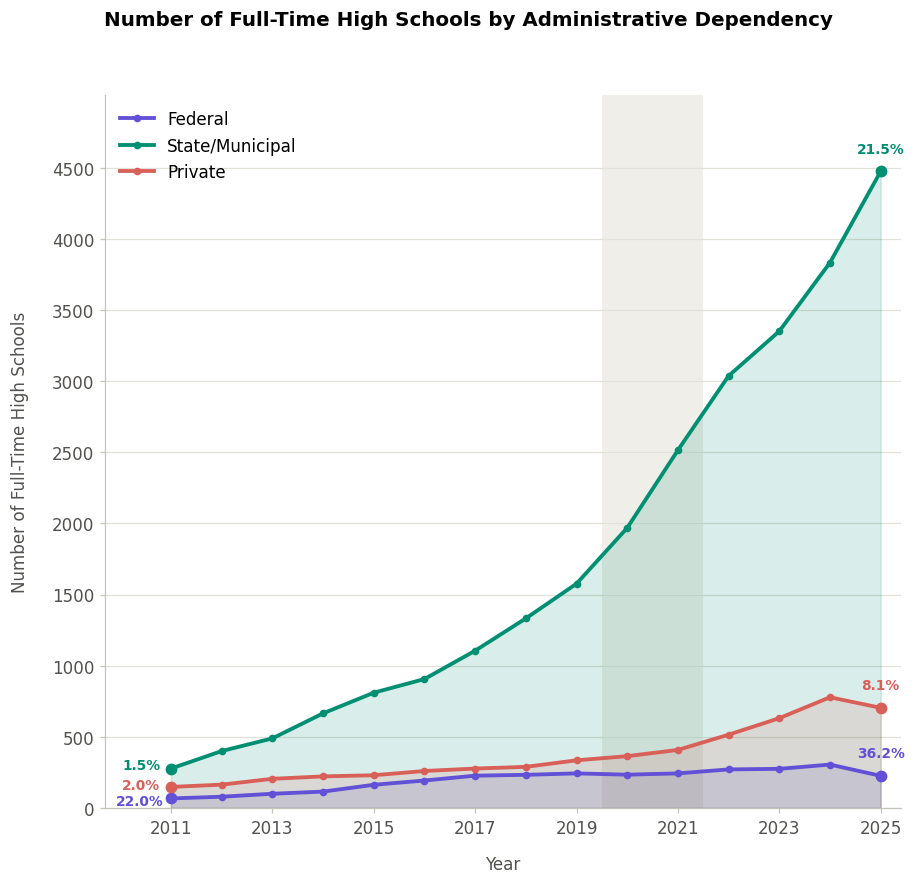

In [173]:
# ----------------------------------------------------------
# 1. CONFIGURAÇÃO DA FIGURA
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 9))

# Destaque do período pandêmico
sombra_pandemia(ax)

# Posições dos percentuais no primeiro ano
# Formato: (deslocamento x, deslocamento y, alinhamento, ancoragem)

POSICOES_INICIO = {
    "Estadual/Municipal": (-32, -2, "left", "bottom"),
    "Privada": (-32, 6, "left", "top"),
    "Federal": (-36, -6, "left", "bottom")
}


# ----------------------------------------------------------
# 2. ÁREAS PREENCHIDAS E LINHAS POR DEPENDÊNCIA
# ----------------------------------------------------------

for dep in DEPS_GRAFICO1:

    # Dados da dependência
    dados = (
        tabela_grafico1.loc[
            tabela_grafico1["DEP"] == dep
        ]
        .sort_values("ANO")
        .copy()
    )

    if dados.empty:
        continue

    anos = dados["ANO"].to_numpy()
    valores = dados["integrais"].to_numpy()

    cor = COR_DEPENDENCIA[dep]

    # Área preenchida
    ax.fill_between(
        anos,
        valores,
        0,
        color=cor,
        alpha=0.15,
        zorder=1
    )

    # Linha principal: quantidade absoluta
    ax.plot(
        anos,
        valores,
        color=cor,
        linewidth=2.5,
        marker="o",
        markersize=4,
        label=TEXTOS["dependencias"][dep],
        zorder=2
    )

    # Destaque dos pontos inicial e final
    ax.scatter(
        [anos[0], anos[-1]],
        [valores[0], valores[-1]],
        color=cor,
        s=45,
        zorder=3
    )

    # ------------------------------------------------------
    # 3. RÓTULOS PERCENTUAIS
    # ------------------------------------------------------

    for pos in [0, -1]:

        linha = dados.iloc[pos]
        percentual = linha["pct_integrais"]

        if pd.isna(percentual):
            continue

        if pos == 0:

            # Primeiro ano: percentuais distribuídos ao lado
            dx, dy, ha, va = POSICOES_INICIO[dep]

        else:

            # Último ano: percentuais centralizados acima
            dx = 0
            dy = 10
            ha = "center"
            va = "bottom"

        ax.annotate(
            f"{percentual:.1f}%",
            xy=(linha["ANO"], linha["integrais"]),
            xytext=(dx, dy),
            textcoords="offset points",
            ha=ha,
            va=va,
            fontsize=9,
            fontweight="semibold",
            color=cor,
            annotation_clip=False,
            zorder=4
        )


# ----------------------------------------------------------
# 4. EIXOS E ESCALAS
# ----------------------------------------------------------

# Limites dinâmicos do eixo Y
maximo = tabela_grafico1["integrais"].max()

ax.set_ylim(
    bottom=0,
    top=maximo * 1.12
)

# Marcações do eixo Y em intervalos de 500
limite_marcas = int(np.ceil(maximo / 500) * 500)

ax.set_yticks(
    np.arange(0, limite_marcas + 1, 500)
)

# Eixo Y
ax.set_ylabel(
    "Number of Full-Time High Schools",
    labelpad=15
)

# Eixo X
ax.set_xlabel(
    TEXTOS["ano"],
    labelpad=12
)

# Marcações dos anos
eixo_anos(
    ax,
    sorted(tabela_grafico1["ANO"].unique().tolist())
)

# Espaço adicional antes e depois do período
ano_min = tabela_grafico1["ANO"].min()
ano_max = tabela_grafico1["ANO"].max()

ax.set_xlim(
    left=ano_min - 1.3,
    right=ano_max + 0.4
)


# ----------------------------------------------------------
# 5. ESTÉTICA E LEGENDA
# ----------------------------------------------------------

ax.grid(
    axis="y",
    color=GRADE
)

ax.grid(
    axis="x",
    visible=False
)

ax.legend(
    loc="upper left",
    frameon=False,
    ncol=1
)


# ----------------------------------------------------------
# 6. TÍTULO
# ----------------------------------------------------------

fig.suptitle(
    "Number of Full-Time High Schools by Administrative Dependency",
    x=0.52,
    y=0.95,
    ha="center",
    fontsize=13,
    fontweight="semibold"
)


# ----------------------------------------------------------
# 7. AJUSTE FINAL E EXPORTAÇÃO
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0.04, 0.06, 0.98, 0.92]
)

salvar(
    fig,
    "g1_expansao_nacional_quantidade_escolas"
)

plt.show()

## 6. Gráfico 2

### Tabela

In [174]:
# ==========================================================
# GRÁFICO 2 — EXPANSÃO REGIONAL
# Escolas integrais por região
# ==========================================================


# ----------------------------------------------------------
# 1. SELEÇÃO DOS DADOS
# ----------------------------------------------------------

print(
    "Dependências disponíveis:",
    sorted(df_analise["DEP"].dropna().unique())
)

dados_grafico2 = (
    df_analise.loc[
        df_analise["DEP"].isin(DEPS_GRAFICO2)
        & df_analise["ANO"].between(*ANOS_EXPANSAO)
    ]
    .copy()
)

# Conferência de duplicatas escola-ano
duplicadas_grafico2 = int(
    dados_grafico2.duplicated(
        ["ANO", "CO_ESCOLA"]
    ).sum()
)

print(
    f"Duplicatas escola-ano na análise regional: "
    f"{duplicadas_grafico2}"
)

assert duplicadas_grafico2 == 0, (
    "Foram encontradas duplicatas escola-ano. "
    "Verifique os dados antes de agregar."
)


# ----------------------------------------------------------
# 2. AGREGAÇÃO POR REGIÃO E ANO
# ----------------------------------------------------------

tabela_grafico2 = (
    dados_grafico2
    .groupby(["REGIAO", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual regional de escolas integrais
tabela_grafico2["pct_integrais"] = (
    100
    * tabela_grafico2["integrais"]
    / tabela_grafico2["escolas"]
)


# ----------------------------------------------------------
# 3. MATRIZ DE PERCENTUAIS REGIONAIS
# ----------------------------------------------------------

anos_grafico2 = sorted(
    tabela_grafico2["ANO"].unique().tolist()
)

percentuais_regionais = (
    tabela_grafico2
    .pivot(
        index="REGIAO",
        columns="ANO",
        values="pct_integrais"
    )
    .reindex(index=REGIOES)
    .reindex(columns=anos_grafico2)
    .astype(float)
)


# ----------------------------------------------------------
# 4. AGREGAÇÃO NACIONAL — BRASIL
# ----------------------------------------------------------

brasil_grafico2 = (
    dados_grafico2
    .groupby("ANO")
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
)

# Percentual nacional
brasil_grafico2["pct_integrais"] = (
    100
    * brasil_grafico2["integrais"]
    / brasil_grafico2["escolas"]
)


# ----------------------------------------------------------
# 5. MATRIZ COMPLETA COM BRASIL
# ----------------------------------------------------------

NOME_BRASIL = "Brazil"

percentual_brasil = (
    brasil_grafico2["pct_integrais"]
    .reindex(anos_grafico2)
    .rename(NOME_BRASIL)
)

percentuais_completo = pd.concat([
    percentual_brasil.to_frame().T,
    percentuais_regionais
])


# ----------------------------------------------------------
# 6. EXPORTAÇÃO DAS TABELAS
# ----------------------------------------------------------

tabela_grafico2.to_csv(
    PASTA_SAIDA / "tab2_expansao_regional_ano.csv",
    index=False,
    encoding="utf-8-sig"
)

brasil_grafico2.to_csv(
    PASTA_SAIDA / "tab2_expansao_nacional_ano.csv",
    encoding="utf-8-sig"
)

percentuais_completo.to_csv(
    PASTA_SAIDA / "tab2_percentuais_regionais_brasil.csv",
    encoding="utf-8-sig"
)


# ----------------------------------------------------------
# 7. CONFERÊNCIA DOS RESULTADOS
# ----------------------------------------------------------

print("\nPERCENTUAL DE ESCOLAS INTEGRAIS POR REGIÃO E BRASIL:")

display(
    percentuais_completo.round(2)
)

print("\nCONTAGENS NACIONAIS:")

display(
    brasil_grafico2.round(2)
)

Dependências disponíveis: ['Estadual/Municipal', 'Federal', 'Privada']
Duplicatas escola-ano na análise regional: 0

PERCENTUAL DE ESCOLAS INTEGRAIS POR REGIÃO E BRASIL:


ANO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Brazil,1.47,2.12,2.57,3.47,4.18,4.64,5.61,6.73,7.94,9.92,12.58,15.07,16.44,18.74,21.53
Norte,1.31,1.65,1.92,2.76,3.4,2.46,3.61,3.64,5.07,5.62,6.08,7.18,7.71,9.75,11.9
Nordeste,3.69,5.54,6.35,7.44,8.72,9.44,10.96,13.51,16.5,19.94,21.98,24.53,26.38,31.44,35.3
Centro-Oeste,0.83,0.7,1.59,2.23,2.2,2.24,4.74,6.82,7.68,10.01,12.41,17.42,19.4,19.34,19.57
Sudeste,0.3,0.65,1.1,2.14,2.89,3.89,4.55,5.36,5.86,7.98,12.6,16.03,17.76,19.19,21.24
Sul,1.14,1.28,1.2,1.67,1.84,1.6,1.74,1.65,2.0,2.27,2.65,2.75,3.1,4.83,8.86



CONTAGENS NACIONAIS:


,escolas,integrais,pct_integrais
ANO,,,
2011,18810,277,1.47
2012,18902,400,2.12
2013,19006,489,2.57
2014,19160,665,3.47
2015,19367,810,4.18
2016,19527,906,4.64
2017,19706,1105,5.61
2018,19781,1332,6.73
2019,19840,1576,7.94


### Gráfico

Salvo: figuras_poster\g2_expansao_regional_heatmap.png / .svg


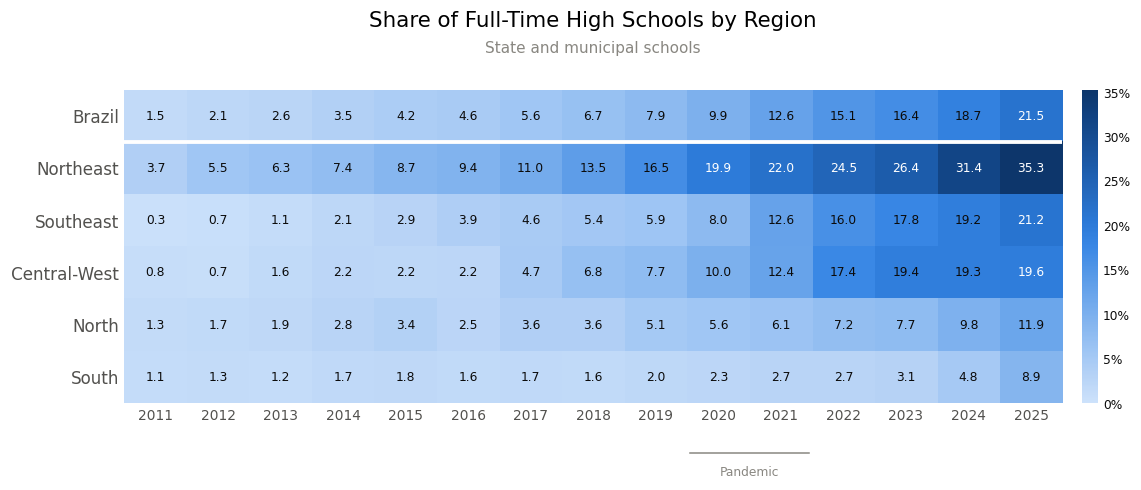

Salvo: figuras_poster\g2_expansao_regional_heatmap.png / .svg


In [182]:
# ==========================================================
# GRÁFICO 2 — MAPA DE CALOR REGIONAL
# Participação das escolas integrais
# ==========================================================
from matplotlib.ticker import PercentFormatter

# ----------------------------------------------------------
# 1. ORGANIZAÇÃO DA MATRIZ
# ----------------------------------------------------------

# Ordenar regiões pelo percentual do último ano
ordem_regioes = (
    percentuais_regionais[anos_grafico2[-1]]
    .sort_values(
        ascending=False,
        na_position="last"
    )
    .index.tolist()
)

# Brasil sempre aparece primeiro
matriz_grafico2 = pd.concat([
    percentuais_completo.loc[[NOME_BRASIL]],
    percentuais_completo.loc[ordem_regioes]
]).astype(float)

# Tradução dos nomes das regiões
TRADUCAO_REGIOES = {
    "Nordeste": "Northeast",
    "Sudeste": "Southeast",
    "Centro-Oeste": "Central-West",
    "Norte": "North",
    "Sul": "South"
}

matriz_grafico2 = matriz_grafico2.rename(
    index=TRADUCAO_REGIOES
)

linhas_grafico2 = matriz_grafico2.index.tolist()


# ----------------------------------------------------------
# 2. CONSTRUÇÃO DO MAPA DE CALOR
# ----------------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "azul",
    RAMPA_AZUL
)

vmax = max(
    float(np.nanmax(matriz_grafico2.to_numpy())),
    1
)

fig, ax = plt.subplots(
    figsize=(11, 0.55 * len(linhas_grafico2) + 1.6)
)

im = ax.imshow(
    matriz_grafico2.to_numpy(),
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=vmax
)


# ----------------------------------------------------------
# ESCALA DE CORES
# ----------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="vertical",
    fraction=0.025,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=0)
)


cbar.ax.tick_params(
    labelsize=8,
    colors=TINTA,
    length=0
)

cbar.outline.set_visible(False)

# ----------------------------------------------------------
# 3. EIXOS E IDENTIFICAÇÃO DAS REGIÕES
# ----------------------------------------------------------

ax.set_xticks(
    range(len(anos_grafico2))
)

ax.set_xticklabels(
    anos_grafico2,
    fontsize=9
)

ax.set_yticks(
    range(len(linhas_grafico2))
)

ax.set_yticklabels(
    linhas_grafico2
)

ax.tick_params(length=0)
ax.grid(False)

# Todos os nomes das regiões com peso normal
for label in ax.get_yticklabels():
    label.set_fontweight("normal")

# Separador visual entre Brasil e regiões
ax.axhline(
    0.5,
    color="white",
    linewidth=2.5,
    zorder=5
)

# Remover bordas
for s in ax.spines.values():
    s.set_visible(False)


# ----------------------------------------------------------
# 4. VALORES NAS CÉLULAS
# ----------------------------------------------------------

for i in range(len(linhas_grafico2)):
    for j in range(len(anos_grafico2)):

        valor = matriz_grafico2.iat[i, j]

        if pd.notna(valor):

            ax.text(
                j,
                i,
                f"{valor:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="normal",
                color="white" if valor > 0.55 * vmax else TINTA,
                zorder=4
            )


# ----------------------------------------------------------
# 5. DESTAQUE DO PERÍODO PANDÊMICO
# ----------------------------------------------------------

# Manter os limites originais da matriz
ax.set_ylim(
    len(linhas_grafico2) - 0.5,
    -0.5
)

if all(ano in anos_grafico2 for ano in ANOS_PANDEMIA):

    j0 = anos_grafico2.index(ANOS_PANDEMIA[0])
    j1 = anos_grafico2.index(ANOS_PANDEMIA[1])

    # Coordenadas: x em dados e y relativo ao eixo
    trans = ax.get_xaxis_transform()

    # Traço abaixo dos anos
    ax.plot(
        [j0 - 0.45, j1 + 0.45],
        [-0.16, -0.16],
        transform=trans,
        color=APAGADO,
        lw=1,
        clip_on=False
    )

    # Identificação do período
    ax.text(
        (j0 + j1) / 2,
        -0.20,
        "Pandemic",
        transform=trans,
        ha="center",
        va="top",
        fontsize=8,
        color=APAGADO
    )


# ----------------------------------------------------------
# 6. TÍTULO E SUBTÍTULO
# ----------------------------------------------------------

# Ajustar a área do gráfico antes de posicionar os textos
fig.tight_layout(
    rect=[0.02, 0.04, 0.98, 0.87]
)

# Centro horizontal da área do mapa de calor
posicao = ax.get_position()
centro_mapa = (posicao.x0 + posicao.x1) / 2

# Título
fig.text(
    centro_mapa,
    0.98,
    "Share of Full-Time High Schools by Region",
    ha="center",
    va="top",
    fontsize=14
)

# Subtítulo
fig.text(
    centro_mapa,
    0.925,
    "State and municipal schools",
    ha="center",
    va="top",
    fontsize=10,
    color=APAGADO
)


# ----------------------------------------------------------
# 7. EXPORTAÇÃO
# ----------------------------------------------------------

salvar(
    fig,
    "g2_expansao_regional_heatmap"
)

plt.show()


# ----------------------------------------------------------
# 7. AJUSTE FINAL E EXPORTAÇÃO
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0.02, 0.15, 0.98, 0.87]
)

salvar(
    fig,
    "g2_expansao_regional_heatmap"
)

plt.show()